**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**09 | Full-Development Grouped Cross-Validation**

![Stage 09 scientific workflow](../../images/09_workflow.svg)

**Objective:** Compare three classical classifiers across five participant-disjoint Development folds and examine fold-level and paired participant-level performance.

**Dataset:** All 29 HARTH v2.0 Development participants, using the time-safe, 30-feature window cohort defined in Notebook 08.

**Notebook Scope:** Train and evaluate models within Development only; compare Random Forest and Logistic Regression on the same held-out participants. S023 and S032 remain excluded from this Notebook. Earlier exploratory inspection of those reserved recordings means this is not evidence of strict blind final Test evaluation.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# ------------------------- Repository Configuration --------------------------
from pathlib import Path

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")

# ------------------------ Clone Repository if Missing ------------------------
%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ------------------------------ Open Repository ------------------------------
%cd {repo_path}


/content
/content/human-movement-intelligence


**01. Imports and Environment**

In [2]:
# ======================== 01. Imports and Environment ========================

# ---------------------- Study Environment Configuration ----------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")

# ---------------------- Data Analysis and Visualisation ----------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# ------------------- HARTH Cohort and Evaluation Utilities -------------------
from harth_data import (
    HARTH_SUBJECTS,
    ACTIVITY_NAMES,
    prepare_harth_feature_cohort,
)

from core.data_splitting import audit_group_class_coverage

from core.group_cross_validation import (
    evaluate_group_cross_validation,
    compare_models_by_subject,
)

# --------------------- Plot Style and Environment Check ----------------------
from core.plot_style import plot_style
plot_style()

print("HARTH full-development CV components: ready")


HARTH full-development CV components: ready


**02. Reconstruct the Complete 29-Person Development Cohort**

Reuse the source cohort and windowing settings from Notebook 08. Filter the eight-class task after constructing time-safe windows; retrieve cached recordings or download missing files as needed.

In [3]:
# ============== 02. Reconstruct Full Development Feature Cohort ==============

# ------------------- Reserved Test and Development Cohorts -------------------
RESERVED_TEST = {"S023", "S032"}

DEVELOPMENT_SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)

# -------------------- Eight-Class Task and Test Exclusion --------------------
TASK_CLASSES = tuple(range(1, 9))

assert len(DEVELOPMENT_SUBJECTS) == 29
assert not (set(DEVELOPMENT_SUBJECTS) & RESERVED_TEST)

# ------------------- Development Window and Feature Cohort -------------------
features, metadata, overview, excluded = prepare_harth_feature_cohort(
    subjects=DEVELOPMENT_SUBJECTS,
    data_dir=root / "data/raw/harth_v2",
    task_classes=TASK_CLASSES,  # Use the predefined documented activity classes.
    window_size=100, step_size=50, sampling_rate=50,
)

# ------------------------- Source Feature Alignment --------------------------
assert len(features) == len(metadata)

# ------------------------ Cohort Scope and Exclusions ------------------------
print("Development feature matrix:", features.shape)

print("Excluded out-of-task windows:", int(overview["excluded_windows"].sum()))
print("Reserved Test participants loaded: NO")


Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Input windows: (7441, 6, 100)
Feature matrix: (7441, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Input windows: (7564, 6, 100)
Feature matrix: (7564, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | 

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:203: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Input windows: (3335, 6, 100)
Feature matrix: (3335, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S031.csv


/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:203: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Input windows: (4411, 6, 100)
Feature matrix: (4411, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Input windows: (3687, 6, 100)
Feature matrix: (3687, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Input windows: (3351, 6, 100)
Feature matr

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:203: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Input windows: (3468, 6, 100)
Feature matrix: (3468, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Input windows: (3355, 6, 100)
Feature matrix: (3355, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Eligible dataset: 29 subjects, 132,397 windows, 30 features
Development feature matrix: (132397, 30)
Excluded out-of-task windows: 11708
Reserved Test participants loaded: NO


**03. Verify Subject-Disjoint Folds and Class Coverage**

Check that Train and Validation have no participant overlap and that the predefined classes are represented in each fold. The saved fold audit reports complete class coverage, but this alone does not establish model performance.

In [4]:
# =============== 03. Audit All Five Participant-Disjoint Folds ===============

# -------------------- Participant-Disjoint Fold Coverage ---------------------
coverage, fold_audit = audit_group_class_coverage(
    labels=metadata["label"].to_numpy(),
    group_ids=metadata["subject_id"].to_numpy(),
    classes=TASK_CLASSES, n_splits=5,
)

# --------------------- Fold Membership and Class Support ---------------------
display(fold_audit[[
    "fold", "train_subjects", "validation_subjects",
    "train_windows", "validation_windows",
    "missing_train_classes", "missing_validation_classes",
]])

# --------------------------- Class Presence Checks ---------------------------
assert not fold_audit["missing_train_classes"].map(bool).any()

assert not fold_audit["missing_validation_classes"].map(bool).any()

print("Fold class-coverage audit: PASSED")


Group audit: 29 subjects, 132,397 windows, 8 declared classes, 5 folds
Folds missing training classes: 0


,fold,train_subjects,validation_subjects,train_windows,validation_windows,missing_train_classes,missing_validation_classes
0,1,"S006, S008, S009, S012, S013, S014, S016, S017...","S010, S015, S022, S026, S037, S038",106134,26263,(),()
1,2,"S006, S009, S010, S012, S013, S014, S015, S017...","S008, S016, S025, S028, S033, S036",105037,27360,(),()
2,3,"S006, S008, S010, S013, S015, S016, S017, S018...","S009, S012, S014, S019, S027, S030",106915,25482,(),()
3,4,"S008, S009, S010, S012, S014, S015, S016, S017...","S006, S013, S018, S029, S031, S034",104400,27997,(),()
4,5,"S006, S008, S009, S010, S012, S013, S014, S015...","S017, S020, S021, S024, S035",107102,25295,(),()


Fold class-coverage audit: PASSED


**04. Compare Three Models Across Five Development Folds**

Refit each classifier within every fold. Logistic Regression scaling uses that fold's Train observations only. Reserved Test recordings are not loaded.

In [5]:
# =============== 04. Evaluate Classical Models with GroupKFold ===============

# ------------------ Five-Fold Development Model Evaluation -------------------
fold_results, subject_results, summary = evaluate_group_cross_validation(
    features=features.to_numpy(),
    labels=metadata["label"].to_numpy(),
    group_ids=metadata["subject_id"].to_numpy(),
    classes=TASK_CLASSES,
    n_splits=5, random_state=42,
)

# ---------------------- Model-Level Cross-Fold Summary -----------------------
display(summary.round(4))

# --------------------------- Held-Out Fold Details ---------------------------
display(fold_results[[
    "fold", "model", "validation_subjects",
    "validation_windows", "validation_classes_present",
    "macro_f1", "balanced_accuracy",
]].round(4))


Fold 1: Train=23 subjects, Validation=6 subjects
Dummy (most frequent): Validation Macro F1 = 0.0616
Logistic Regression: Validation Macro F1 = 0.8476
Random Forest: Validation Macro F1 = 0.8313
Fold 2: Train=23 subjects, Validation=6 subjects
Dummy (most frequent): Validation Macro F1 = 0.0810
Logistic Regression: Validation Macro F1 = 0.7915
Random Forest: Validation Macro F1 = 0.8680
Fold 3: Train=23 subjects, Validation=6 subjects
Dummy (most frequent): Validation Macro F1 = 0.0927
Logistic Regression: Validation Macro F1 = 0.7540
Random Forest: Validation Macro F1 = 0.8857
Fold 4: Train=23 subjects, Validation=6 subjects
Dummy (most frequent): Validation Macro F1 = 0.0857
Logistic Regression: Validation Macro F1 = 0.6942
Random Forest: Validation Macro F1 = 0.8094
Fold 5: Train=24 subjects, Validation=5 subjects
Dummy (most frequent): Validation Macro F1 = 0.0862
Logistic Regression: Validation Macro F1 = 0.7696
Random Forest: Validation Macro F1 = 0.7818


,model,fold_macro_f1_mean,fold_macro_f1_sd,fold_macro_f1_min,fold_macro_f1_max,subject_macro_f1_fixed_mean,subject_macro_f1_observed_mean
0,Random Forest,0.8353,0.0423,0.7818,0.8857,0.7310,0.8182
1,Logistic Regression,0.7714,0.0559,0.6942,0.8476,0.6945,0.7716
2,Dummy (most frequent),0.0815,0.0118,0.0616,0.0927,0.0616,0.0677


,fold,model,validation_subjects,validation_windows,validation_classes_present,macro_f1,balanced_accuracy
0,1,Logistic Regression,"S010, S015, S022, S026, S037, S038",26263,8,0.8476,0.9143
1,1,Random Forest,"S010, S015, S022, S026, S037, S038",26263,8,0.8313,0.8189
2,1,Dummy (most frequent),"S010, S015, S022, S026, S037, S038",26263,8,0.0616,0.1250
3,2,Random Forest,"S008, S016, S025, S028, S033, S036",27360,8,0.8680,0.8825
4,2,Logistic Regression,"S008, S016, S025, S028, S033, S036",27360,8,0.7915,0.9048
5,2,Dummy (most frequent),"S008, S016, S025, S028, S033, S036",27360,8,0.0810,0.1250
6,3,Random Forest,"S009, S012, S014, S019, S027, S030",25482,8,0.8857,0.8640
7,3,Logistic Regression,"S009, S012, S014, S019, S027, S030",25482,8,0.7540,0.9010
8,3,Dummy (most frequent),"S009, S012, S014, S019, S027, S030",25482,8,0.0927,0.1250
9,4,Random Forest,"S006, S013, S018, S029, S031, S034",27997,8,0.8094,0.8380


**05. Visualise Variation in Held-Out Macro F1**

Compare fold-level Macro F1 across models, accounting for differences in participant composition and window counts. These folds share the Development cohort and do not represent independent replications.

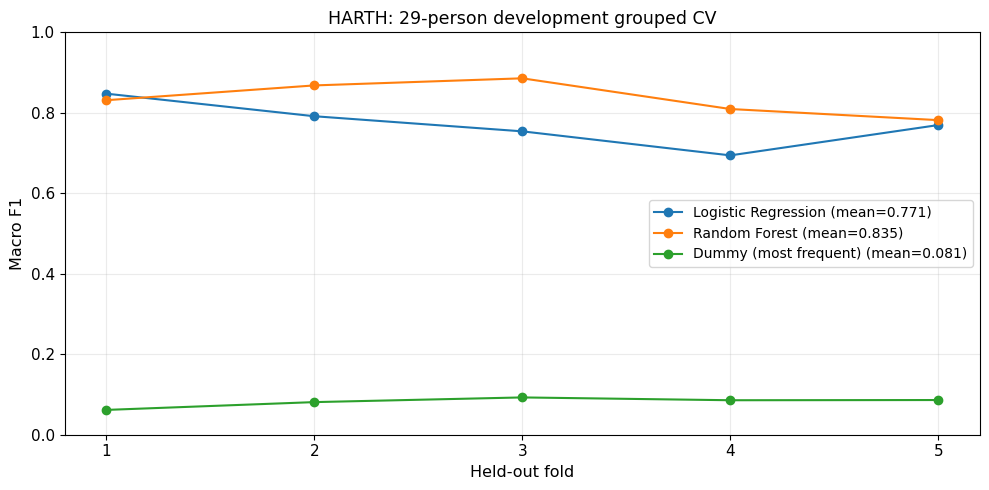

In [6]:
# ================= 05. Visualise Five-Fold Model Performance =================

# ---------------------- Fold-Level Macro F1 Comparison -----------------------
fig, ax = plt.subplots(figsize=(10, 5))

for model_name, table in fold_results.groupby("model", sort=False):
    table = table.sort_values("fold")
    ax.plot(table["fold"], table["macro_f1"], marker="o",
            label=f"{model_name} (mean={table['macro_f1'].mean():.3f})")

ax.set(title="HARTH: 29-person development grouped CV",
       xlabel="Held-out fold", ylabel="Macro F1",
       ylim=(0, 1), xticks=[1, 2, 3, 4, 5])
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()


**06. Compare Random Forest and Logistic Regression by Person**

Pair fixed eight-class Macro F1 scores for the same 29 held-out Development participants. The metric `difference_a_minus_b` is Random Forest minus Logistic Regression; positive values favour Random Forest.

,subject_id,score_a,score_b,difference_a_minus_b
0,S006,0.7265,0.6126,0.1139
1,S008,0.5334,0.5095,0.0239
2,S009,0.4302,0.3337,0.0965
3,S010,0.4505,0.5094,-0.0589
4,S012,0.9066,0.8809,0.0257
5,S013,0.8506,0.9123,-0.0618
6,S014,0.8614,0.7003,0.1611
7,S015,0.7815,0.8058,-0.0244
8,S016,0.9251,0.8803,0.0448
9,S017,0.7281,0.7644,-0.0363


,model_a,model_b,metric,participants,mean_difference,median_difference,model_a_wins,model_b_wins,ties
0,Random Forest,Logistic Regression,macro_f1_fixed_task,29,0.036542,0.025714,19,10,0


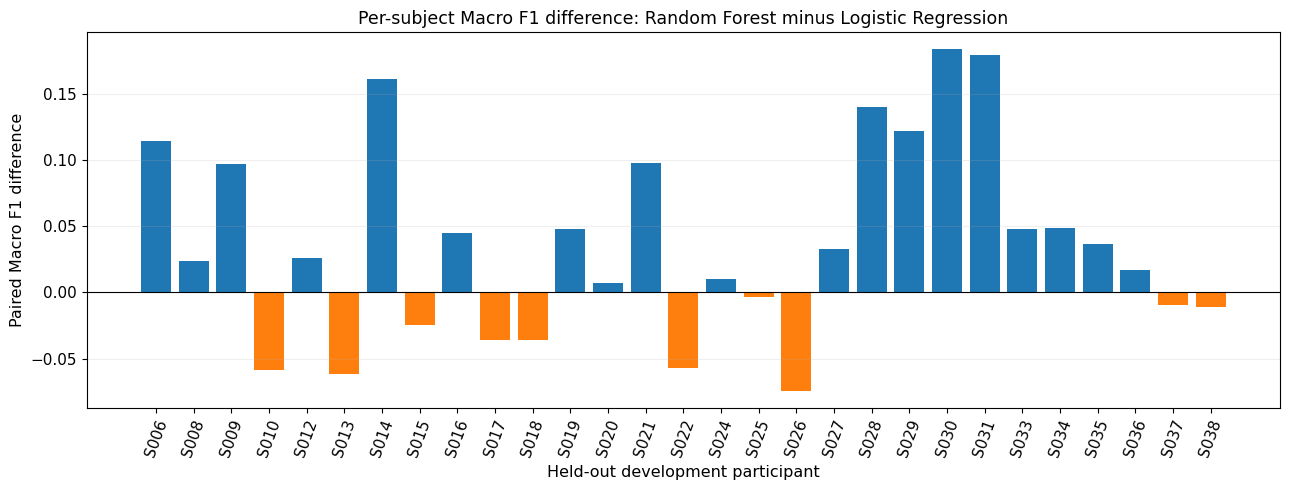

In [7]:
# ============== 06. Pair Random Forest and Logistic Regression ===============

# -------------------- Paired Participant Model Comparison --------------------
paired, paired_summary = compare_models_by_subject(
    subject_results,
    model_a="Random Forest",
    model_b="Logistic Regression",
    score_column="macro_f1_fixed_task",  # Use the same eight-class metric for both models.
)

# --------------------------- Paired Model Results ----------------------------
display(paired.round(4))

display(pd.DataFrame([paired_summary]))

# ------------------------ Signed Macro F1 Differences ------------------------
fig, ax = plt.subplots(figsize=(13, 5))

bar_colours = ["tab:blue" if value >= 0 else "tab:orange"
               for value in paired["difference_a_minus_b"]]

# -------------------- Participant-Level Difference Figure --------------------
ax.bar(paired["subject_id"], paired["difference_a_minus_b"], color=bar_colours)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Per-subject Macro F1 difference: Random Forest minus Logistic Regression",
       xlabel="Held-out development participant", ylabel="Paired Macro F1 difference")
ax.tick_params(axis="x", rotation=70)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()


**07. Compare Activity Support and Individual Model Scores**

Report class availability and fixed-task Macro F1 for each participant. Interpret individual differences alongside activity support rather than relying only on aggregate scores.

In [8]:
# =============== 07. Compare Source Class Support and Results ================

# --------------------- Activity Class Support by Person ----------------------
person_support = pd.DataFrame({
    "subject_id": coverage.index,
    "eligible_windows": coverage.sum(axis=1).to_numpy(),
    "observed_classes": (coverage > 0).sum(axis=1).to_numpy(),
})

# ------------------------ Fixed-Task Scores by Model -------------------------
comparison = subject_results.pivot(
    index="subject_id", columns="model", values="macro_f1_fixed_task"
).reset_index()

# ---------------------- Participant Evidence Alignment -----------------------
participant_table = person_support.merge(comparison, on="subject_id", how="left")

# ---------------------------- Participant Summary ----------------------------
display(participant_table.round(4))

print("Independent development subjects represented:", len(participant_table))


,subject_id,eligible_windows,observed_classes,Dummy (most frequent),Logistic Regression,Random Forest
0,S006,6708,7,0.1072,0.6126,0.7265
1,S008,7392,6,0.1103,0.5095,0.5334
2,S009,201,4,0.0000,0.3337,0.4302
3,S010,6077,6,0.0331,0.5094,0.4505
4,S012,7309,8,0.1149,0.8809,0.9066
5,S013,6402,8,0.1025,0.9123,0.8506
6,S014,6299,8,0.1070,0.7003,0.8614
7,S015,7453,8,0.0857,0.8058,0.7815
8,S016,6272,8,0.0941,0.8803,0.9251
9,S017,6678,8,0.0985,0.7644,0.7281


Independent development subjects represented: 29


**08. Scientific Quality Gate and Evidence Boundaries**

Verify the five-fold results, participant separation, source integrity and reserved Test exclusion. Because some properties of S023 and S032 were inspected in earlier exploratory work, do not describe the broader research as strictly preregistered and blind.

In [9]:
# ============ 08. Development GroupKFold Scientific Quality Gate =============

# ------------------- Development Cohort and Test Exclusion -------------------
assert len(DEVELOPMENT_SUBJECTS) == len(set(DEVELOPMENT_SUBJECTS)) == 29

assert not (set(DEVELOPMENT_SUBJECTS) & RESERVED_TEST)

# ------------------ Participant and Fold Evidence Coverage -------------------
assert len(subject_results["subject_id"].unique()) == 29

assert not (set(subject_results["subject_id"]) & RESERVED_TEST)

assert len(fold_results) == 5 * 3

assert len(paired) == 29

# ------------------ Unique Evaluation and Feature Integrity ------------------
assert subject_results.groupby(["model", "subject_id"]).size().eq(1).all()

assert np.isfinite(features.to_numpy()).all()

# -------------------- Quality Gate and Evidence Boundary ---------------------
print("Full-development GroupKFold: PASSED")

print("Original final Test loaded or scored: NO")

print("Final independent benchmark claim: NOT SUPPORTED")


Full-development GroupKFold: PASSED
Original final Test loaded or scored: NO
Final independent benchmark claim: NOT SUPPORTED
